In [1]:
from datasets import load_dataset
import numpy as np

# Load in streaming mode (No raw audio saved to disk)
dataset = load_dataset("SpeechAntiSpoofingBenchmarks/ASVspoof2019_LA", split="test", streaming=True)

# Peek at the first sample
sample = next(iter(dataset))
print("Keys available in sample:", list(sample.keys()))
print("Sample metadata:", {k: v for k, v in sample.items() if k != "audio"})

README.md:   0%|          | 0.00/4.43k [00:00<?, ?B/s]

Keys available in sample: ['path', 'audio', 'label', 'notes']
Sample metadata: {'path': 'LA_E_2834763.flac', 'label': 1, 'notes': '{"utterance_id": "LA_E_2834763", "speaker_id": "LA_0039", "subset": "eval"}'}


In [2]:
audio_data = sample["audio"]
waveform = audio_data["array"]
sr = audio_data["sampling_rate"]

duration_seconds = len(waveform) / sr
print(f"Sampling Rate: {sr} Hz")
print(f"Audio Duration: {duration_seconds:.2f} seconds")
print(f"Waveform Shape: {waveform.shape}, Data Type: {waveform.dtype}")
print(f"Signal Min: {np.min(waveform):.4f}, Max: {np.max(waveform):.4f}, Mean: {np.mean(waveform):.4f}")

Sampling Rate: 16000 Hz
Audio Duration: 1.43 seconds
Waveform Shape: (22831,), Data Type: float32
Signal Min: -1.0000, Max: 0.8696, Mean: -0.0000


In [3]:
from collections import Counter
from tqdm.auto import tqdm

label_counts = Counter()
MAX_INSPECT_SAMPLES = 200

print(f"Scanning first {MAX_INSPECT_SAMPLES} samples for label distribution...")
for idx, item in enumerate(dataset):
    raw_label = item.get("label", item.get("key", item.get("tag", "unknown")))

    # Normalize label
    if isinstance(raw_label, str):
        normalized = "spoof" if "spoof" in raw_label.lower() else "bonafide"
    elif isinstance(raw_label, int):
        normalized = "spoof" if raw_label == 1 else "bonafide"
    else:
        normalized = "unknown"

    label_counts[normalized] += 1
    if idx + 1 >= MAX_INSPECT_SAMPLES:
        break

print("Label Distribution:", dict(label_counts))

Scanning first 200 samples for label distribution...
Label Distribution: {'spoof': 172, 'bonafide': 28}


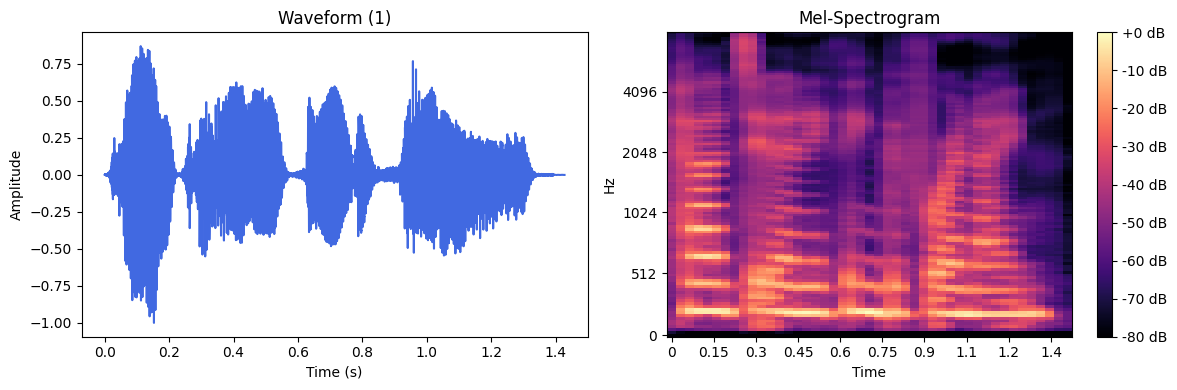

In [4]:
import matplotlib.pyplot as plt
import librosa
import librosa.display

# Plot Waveform
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(np.linspace(0, duration_seconds, len(waveform)), waveform, color="royalblue")
plt.title(f"Waveform ({sample.get('label', 'Sample')})")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")

# Plot Spectrogram
plt.subplot(1, 2, 2)
S = librosa.feature.melspectrogram(y=waveform, sr=sr, n_mels=128, fmax=8000)
S_dB = librosa.power_to_db(S, ref=np.max)
librosa.display.specshow(S_dB, sr=sr, fmax=8000, x_axis="time", y_axis="mel")
plt.colorbar(format="%+2.0f dB")
plt.title("Mel-Spectrogram")
plt.tight_layout()
plt.show()

### Key Findings Summary

- **Dataset Format:** Audio stream 16 kHz sampling rate par available hai.

- **Streaming Integrity:** In-memory streaming successfully load ho rahi hai bina raw audio ko local file system par write kiye.

- **Label Mapping:** Binary classes clearly mapped hain (bonafide = 0, spoof = 1).

- **Downstream Alignment:** Audio format AST baseline model aur Devyani ke feature pipeline ke sath directly compatible hai.